In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_auc_score
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility settings
SEEDS = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

print("TensorFlow version:", tf.__version__)
print("Number of seeds:", len(SEEDS))
print("Seeds:", SEEDS)

TensorFlow version: 2.21.0
Number of seeds: 10
Seeds: [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]


In [2]:
def create_data_split(y, snr, random_state):

    indices = np.arange(len(y))

    # Joint stratification by occupancy label and SNR
    groups = np.array([
        f"{label}_{s}"
        for label, s in zip(y, snr)
    ])

    # 70% training, 30% temporary
    train_idx, temp_idx = train_test_split(
        indices,
        test_size=0.30,
        random_state=random_state,
        stratify=groups
    )

    # Split remaining 30% equally
    temp_groups = groups[temp_idx]

    val_idx, test_idx = train_test_split(
        temp_idx,
        test_size=0.50,
        random_state=random_state,
        stratify=temp_groups
    )

    return train_idx, val_idx, test_idx


print("Data splitting function created successfully.")

Data splitting function created successfully.


In [4]:
data = np.load("spectrum_sensing_dataset.npz")
X = data["X"]
y = data["y"]
snr = data["snr"]

In [5]:
test_train, test_val, test_test = create_data_split(
    y, snr, random_state=42
)

print("Training samples:", len(test_train))
print("Validation samples:", len(test_val))
print("Testing samples:", len(test_test))

print("\nTotal samples:", len(test_train) + len(test_val) + len(test_test))

Training samples: 9800
Validation samples: 2100
Testing samples: 2100

Total samples: 14000


In [6]:
def build_cnn():

    model = Sequential([
        Input(shape=(256, 2)),

        Conv1D(
            filters=32,
            kernel_size=5,
            activation="relu",
            padding="same"
        ),

        MaxPooling1D(pool_size=2),

        Conv1D(
            filters=64,
            kernel_size=3,
            activation="relu",
            padding="same"
        ),

        GlobalAveragePooling1D(),

        Dense(64, activation="relu"),

        Dropout(0.3),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Verify architecture
test_model = build_cnn()

print("CNN training function created.")
print("Total parameters:", test_model.count_params())

CNN training function created.
Total parameters: 10785


In [7]:
def evaluate_cnn_model(model, X_val, y_val, X_test, y_test):

    # Validation probabilities
    val_prob = model.predict(X_val, verbose=0).ravel()

    # Calibrate threshold using validation H0
    threshold = np.quantile(
        val_prob[y_val == 0],
        0.95,
        method="higher"
    )

    # Test probabilities
    test_prob = model.predict(X_test, verbose=0).ravel()

    # Apply calibrated threshold
    test_pred = (test_prob > threshold).astype(int)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test.astype(int),
        test_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, test_pred),
        "Pd": tp / (tp + fn),
        "Pfa": fp / (fp + tn),
        "Pm": fn / (fn + tp),
        "ROC_AUC": roc_auc_score(y_test, test_prob)
    }


print("CNN evaluation function created successfully.")

CNN evaluation function created successfully.


In [8]:
# Load AWGN dataset
data = np.load("spectrum_sensing_dataset.npz")

X_complex = data["X"]
y = data["y"]
snr = data["snr"]

# Convert complex IQ to two-channel float32
X_iq = np.stack(
    [X_complex.real, X_complex.imag],
    axis=-1
).astype(np.float32)

awgn_cnn_results = []

for seed in SEEDS:

    print(f"\n========== SEED {seed} ==========")

    # Set random seeds
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

    # Create split
    train_idx, val_idx, test_idx = create_data_split(
        y, snr, random_state=seed
    )

    X_train = X_iq[train_idx]
    X_val = X_iq[val_idx]
    X_test = X_iq[test_idx]

    y_train = y[train_idx].astype(np.float32)
    y_val = y[val_idx].astype(np.float32)
    y_test = y[test_idx].astype(np.float32)

    # Normalize using training data only
    channel_mean = np.mean(
        X_train, axis=(0, 1), keepdims=True
    )

    channel_std = np.std(
        X_train, axis=(0, 1), keepdims=True
    )

    channel_std = np.maximum(channel_std, 1e-8)

    X_train_scaled = (X_train - channel_mean) / channel_std
    X_val_scaled = (X_val - channel_mean) / channel_std
    X_test_scaled = (X_test - channel_mean) / channel_std

    # Build fresh CNN
    model = build_cnn()

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=0
    )

    # Train
    history = model.fit(
        X_train_scaled,
        y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=40,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    # Evaluate
    metrics = evaluate_cnn_model(
        model,
        X_val_scaled,
        y_val,
        X_test_scaled,
        y_test
    )

    metrics["Seed"] = seed
    metrics["Epochs"] = len(history.history["loss"])

    awgn_cnn_results.append(metrics)

    print(
        f"Accuracy: {metrics['Accuracy']:.4f} | "
        f"Pd: {metrics['Pd']:.4f} | "
        f"Pfa: {metrics['Pfa']:.4f} | "
        f"AUC: {metrics['ROC_AUC']:.4f} | "
        f"Epochs: {metrics['Epochs']}"
    )

print("\nAll AWGN CNN experiments completed.")


========== SEED 10 ==========
Accuracy: 0.7843 | Pd: 0.5695 | Pfa: 0.0010 | AUC: 0.9069 | Epochs: 40

========== SEED 20 ==========
Accuracy: 0.7838 | Pd: 0.5714 | Pfa: 0.0038 | AUC: 0.9071 | Epochs: 40

========== SEED 30 ==========
Accuracy: 0.7638 | Pd: 0.5705 | Pfa: 0.0429 | AUC: 0.8960 | Epochs: 40

========== SEED 40 ==========
Accuracy: 0.7805 | Pd: 0.5705 | Pfa: 0.0095 | AUC: 0.9051 | Epochs: 40

========== SEED 50 ==========
Accuracy: 0.7814 | Pd: 0.5714 | Pfa: 0.0086 | AUC: 0.9053 | Epochs: 40

========== SEED 60 ==========
Accuracy: 0.7810 | Pd: 0.5705 | Pfa: 0.0086 | AUC: 0.9051 | Epochs: 40

========== SEED 70 ==========
Accuracy: 0.7143 | Pd: 0.4286 | Pfa: 0.0000 | AUC: 0.8724 | Epochs: 40

========== SEED 80 ==========
Accuracy: 0.7619 | Pd: 0.5695 | Pfa: 0.0457 | AUC: 0.8995 | Epochs: 40

========== SEED 90 ==========
Accuracy: 0.7138 | Pd: 0.4286 | Pfa: 0.0010 | AUC: 0.8753 | Epochs: 40

========== SEED 100 ==========
Accuracy: 0.7833 | Pd: 0.5686 | Pfa: 0.0019 | AUC:

In [9]:
# Convert results into DataFrame
awgn_cnn_df = pd.DataFrame(awgn_cnn_results)

# Metrics to summarize
metrics = [
    "Accuracy",
    "Pd",
    "Pfa",
    "Pm",
    "ROC_AUC"
]

# Calculate mean and sample standard deviation
awgn_cnn_summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [
        awgn_cnn_df[m].mean() for m in metrics
    ],
    "Std": [
        awgn_cnn_df[m].std(ddof=1) for m in metrics
    ]
})

print("AWGN CNN STATISTICAL SUMMARY")
print("--------------------------------")
print(awgn_cnn_summary.round(4).to_string(index=False))

# Save individual runs
awgn_cnn_df.to_csv(
    "cnn_statistical_validation_awgn_all_runs.csv",
    index=False
)

# Save summary
awgn_cnn_summary.to_csv(
    "cnn_statistical_validation_awgn_summary.csv",
    index=False
)

print("\nBoth AWGN statistical result files saved.")


AWGN CNN STATISTICAL SUMMARY
--------------------------------
  Metric   Mean    Std
Accuracy 0.7648 0.0279
      Pd 0.5419 0.0597
     Pfa 0.0123 0.0172
      Pm 0.4581 0.0597
 ROC_AUC 0.8979 0.0132

Both AWGN statistical result files saved.


In [10]:
print("INDIVIDUAL AWGN CNN RESULTS")

display(
    awgn_cnn_df[
        ["Seed", "Accuracy", "Pd", "Pfa", "Pm", "ROC_AUC", "Epochs"]
    ].round(4)
)

print("\nDetection probability range:")
print("Minimum:", awgn_cnn_df["Pd"].min())
print("Maximum:", awgn_cnn_df["Pd"].max())

print("\nSeeds with Pd below 50%:")
print(
    awgn_cnn_df.loc[
        awgn_cnn_df["Pd"] < 0.50,
        ["Seed", "Accuracy", "Pd", "Pfa", "ROC_AUC"]
    ].to_string(index=False)
)

INDIVIDUAL AWGN CNN RESULTS


,Seed,Accuracy,Pd,Pfa,Pm,ROC_AUC,Epochs
0,10,0.7843,0.5695,0.0010,0.4305,0.9069,40
1,20,0.7838,0.5714,0.0038,0.4286,0.9071,40
2,30,0.7638,0.5705,0.0429,0.4295,0.8960,40
3,40,0.7805,0.5705,0.0095,0.4295,0.9051,40
4,50,0.7814,0.5714,0.0086,0.4286,0.9053,40
5,60,0.7810,0.5705,0.0086,0.4295,0.9051,40
6,70,0.7143,0.4286,0.0000,0.5714,0.8724,40
7,80,0.7619,0.5695,0.0457,0.4305,0.8995,40
8,90,0.7138,0.4286,0.0010,0.5714,0.8753,40
9,100,0.7833,0.5686,0.0019,0.4314,0.9061,40



Detection probability range:
Minimum: 0.42857142857142855
Maximum: 0.5714285714285714

Seeds with Pd below 50%:
 Seed  Accuracy       Pd      Pfa  ROC_AUC
   70  0.714286 0.428571 0.000000 0.872448
   90  0.713810 0.428571 0.000952 0.875301


In [11]:
diagnostic_results = []

for seed in [70, 90]:

    print(f"\n========== DIAGNOSTIC SEED {seed} ==========")

    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

    # Recreate the original split
    train_idx, val_idx, test_idx = create_data_split(
        y, snr, random_state=seed
    )

    X_train = X_iq[train_idx]
    X_val = X_iq[val_idx]
    X_test = X_iq[test_idx]

    y_train = y[train_idx].astype(np.float32)
    y_val = y[val_idx].astype(np.float32)
    y_test = y[test_idx].astype(np.float32)

    snr_test = snr[test_idx]

    # Training-only normalization
    mean = np.mean(X_train, axis=(0, 1), keepdims=True)
    std = np.maximum(
        np.std(X_train, axis=(0, 1), keepdims=True),
        1e-8
    )

    X_train = (X_train - mean) / std
    X_val = (X_val - mean) / std
    X_test = (X_test - mean) / std

    # Fresh model
    model = build_cnn()

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=40,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    # Validation calibration
    val_prob = model.predict(X_val, verbose=0).ravel()

    threshold = np.quantile(
        val_prob[y_val == 0],
        0.95,
        method="higher"
    )

    val_pred = (val_prob > threshold).astype(int)

    val_tn, val_fp, val_fn, val_tp = confusion_matrix(
        y_val.astype(int),
        val_pred,
        labels=[0, 1]
    ).ravel()

    # Test evaluation
    test_prob = model.predict(X_test, verbose=0).ravel()
    test_pred = (test_prob > threshold).astype(int)

    print("Threshold:", threshold)
    print("Validation Pfa:", val_fp / (val_fp + val_tn))
    print("Best validation loss:", min(history.history["val_loss"]))
    print("Best validation accuracy:", max(history.history["val_accuracy"]))

    for s in np.unique(snr_test):

        mask = snr_test == s

        tn, fp, fn, tp = confusion_matrix(
            y_test[mask].astype(int),
            test_pred[mask],
            labels=[0, 1]
        ).ravel()

        row = {
            "Seed": seed,
            "SNR": s,
            "Pd": tp / (tp + fn),
            "Pfa": fp / (fp + tn)
        }

        diagnostic_results.append(row)

        print(
            f"SNR {s:>3}: "
            f"Pd={row['Pd']:.4f}, "
            f"Pfa={row['Pfa']:.4f}"
        )

diagnostic_df = pd.DataFrame(diagnostic_results)

print("\nDIAGNOSTIC SUMMARY")
print(diagnostic_df.round(4).to_string(index=False))


========== DIAGNOSTIC SEED 70 ==========
Threshold: 0.5568482
Validation Pfa: 0.0
Best validation loss: 0.3518398106098175
Best validation accuracy: 0.7814285755157471
SNR -20: Pd=0.0000, Pfa=0.0000
SNR -15: Pd=0.0000, Pfa=0.0000
SNR -10: Pd=0.0000, Pfa=0.0000
SNR  -5: Pd=0.0000, Pfa=0.0000
SNR   0: Pd=1.0000, Pfa=0.0000
SNR   5: Pd=1.0000, Pfa=0.0000
SNR  10: Pd=1.0000, Pfa=0.0000

========== DIAGNOSTIC SEED 90 ==========
Threshold: 0.5548037
Validation Pfa: 0.0
Best validation loss: 0.3518822491168976
Best validation accuracy: 0.7828571200370789
SNR -20: Pd=0.0000, Pfa=0.0000
SNR -15: Pd=0.0000, Pfa=0.0000
SNR -10: Pd=0.0000, Pfa=0.0000
SNR  -5: Pd=0.0000, Pfa=0.0000
SNR   0: Pd=1.0000, Pfa=0.0067
SNR   5: Pd=1.0000, Pfa=0.0000
SNR  10: Pd=1.0000, Pfa=0.0000

DIAGNOSTIC SUMMARY
 Seed  SNR  Pd    Pfa
   70  -20 0.0 0.0000
   70  -15 0.0 0.0000
   70  -10 0.0 0.0000
   70   -5 0.0 0.0000
   70    0 1.0 0.0000
   70    5 1.0 0.0000
   70   10 1.0 0.0000
   90  -20 0.0 0.0000
   90  -15

In [12]:
# Analyze seed 70 probability distributions

seed = 70

np.random.seed(seed)
tf.keras.utils.set_random_seed(seed)

train_idx, val_idx, test_idx = create_data_split(
    y, snr, random_state=seed
)

X_train = X_iq[train_idx]
X_val = X_iq[val_idx]
X_test = X_iq[test_idx]

y_train = y[train_idx].astype(np.float32)
y_val = y[val_idx].astype(np.float32)
y_test = y[test_idx].astype(np.float32)

snr_test = snr[test_idx]

# Normalize using training data
mean = np.mean(X_train, axis=(0, 1), keepdims=True)
std = np.maximum(
    np.std(X_train, axis=(0, 1), keepdims=True),
    1e-8
)

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

# Train seed-70 CNN
model = build_cnn()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

# Get test probabilities
test_prob = model.predict(X_test, verbose=0).ravel()

# Print probability statistics by SNR and class
for s in np.unique(snr_test):

    print(f"\nSNR = {s} dB")

    for label in [0, 1]:

        mask = (snr_test == s) & (y_test == label)
        scores = test_prob[mask]

        print(
            f"H{label}: "
            f"Mean={np.mean(scores):.4f}, "
            f"Median={np.median(scores):.4f}, "
            f"Min={np.min(scores):.4f}, "
            f"Max={np.max(scores):.4f}"
        )


SNR = -20 dB
H0: Mean=0.5568, Median=0.5568, Min=0.5568, Max=0.5568
H1: Mean=0.5568, Median=0.5568, Min=0.5568, Max=0.5568

SNR = -15 dB
H0: Mean=0.5568, Median=0.5568, Min=0.5568, Max=0.5568
H1: Mean=0.5568, Median=0.5568, Min=0.5568, Max=0.5568

SNR = -10 dB
H0: Mean=0.5568, Median=0.5568, Min=0.5568, Max=0.5568
H1: Mean=0.5568, Median=0.5568, Min=0.5568, Max=0.5568

SNR = -5 dB
H0: Mean=0.0855, Median=0.0766, Min=0.0236, Max=0.2939
H1: Mean=0.5441, Median=0.5568, Min=0.3121, Max=0.5568

SNR = 0 dB
H0: Mean=0.0037, Median=0.0000, Min=0.0000, Max=0.3452
H1: Mean=0.9999, Median=1.0000, Min=0.9954, Max=1.0000

SNR = 5 dB
H0: Mean=0.0000, Median=0.0000, Min=0.0000, Max=0.0000
H1: Mean=1.0000, Median=1.0000, Min=0.9997, Max=1.0000

SNR = 10 dB
H0: Mean=0.0000, Median=0.0000, Min=0.0000, Max=0.0000
H1: Mean=1.0000, Median=1.0000, Min=1.0000, Max=1.0000


In [14]:
from tensorflow.keras.models import Model

# Explicitly build the model using the expected input shape
model.build(input_shape=(None, 256, 2))

# Create intermediate activation model
intermediate_model = Model(
    inputs=model.inputs,
    outputs=model.layers[2].output
)

print("Intermediate model created successfully.")

Intermediate model created successfully.


In [15]:
# Inspect low-SNR activations

for s in [-20, -15, -10]:

    mask = (snr_test == s)
    sample_indices = np.where(mask)[0][:100]

    sample_data = X_test[sample_indices]

    activations = intermediate_model.predict(
        sample_data,
        verbose=0
    )

    output_prob = model.predict(
        sample_data,
        verbose=0
    ).ravel()

    print(f"\nSNR = {s} dB")

    print("Activation mean:", np.mean(activations))
    print("Activation std:", np.std(activations))

    print("Prediction mean:", np.mean(output_prob))
    print("Prediction std:", np.std(output_prob))


SNR = -20 dB
Activation mean: 4.399764
Activation std: 5.668525
Prediction mean: 0.5568481
Prediction std: 1.1920929e-07

SNR = -15 dB
Activation mean: 2.199191
Activation std: 2.8795283
Prediction mean: 0.5568481
Prediction std: 1.1920929e-07

SNR = -10 dB
Activation mean: 1.0115044
Activation std: 1.3386075
Prediction mean: 0.5568481
Prediction std: 1.1920929e-07


In [16]:
# Inspect output variation at every CNN layer

from tensorflow.keras.models import Model
import numpy as np

# Ensure the model has a built computational graph
_ = model(sample_data[:1])

print("Layer-wise activation statistics:\n")

for layer in model.layers:
    intermediate_model = Model(
        inputs=model.inputs,
        outputs=layer.output
    )

    activations = intermediate_model.predict(
        sample_data,
        verbose=0
    )

    print(f"Layer: {layer.name}")
    print("  Shape:", activations.shape)
    print("  Mean:", np.mean(activations))
    print("  Std:", np.std(activations))
    print("  Min:", np.min(activations))
    print("  Max:", np.max(activations))
    print()

Layer-wise activation statistics:

Layer: conv1d_26
  Shape: (100, 256, 32)
  Mean: 0.18512253
  Std: 0.2527156
  Min: 0.0
  Max: 2.4364986

Layer: max_pooling1d_13
  Shape: (100, 128, 32)
  Mean: 0.28287756
  Std: 0.2922248
  Min: 0.0
  Max: 2.4364986

Layer: conv1d_27
  Shape: (100, 128, 64)
  Mean: 1.0115044
  Std: 1.3386075
  Min: 0.0
  Max: 9.368034

Layer: global_average_pooling1d_13
  Shape: (100, 64)
  Mean: 1.0115044
  Std: 1.2368466
  Min: 0.0
  Max: 4.7297497

Layer: dense_26
  Shape: (100, 64)
  Mean: 0.0
  Std: 0.0
  Min: 0.0
  Max: 0.0

Layer: dropout_13
  Shape: (100, 64)
  Mean: 0.0
  Std: 0.0
  Min: 0.0
  Max: 0.0

Layer: dense_27
  Shape: (100, 1)
  Mean: 0.5568481
  Std: 1.1920929e-07
  Min: 0.5568482
  Max: 0.5568482



In [17]:
# Inspect Dense layer output before ReLU activation

dense_layer = model.get_layer("dense_26")

# Extract input to the Dense layer
dense_input_model = Model(
    inputs=model.inputs,
    outputs=model.layers[3].output
)

pooled_features = dense_input_model.predict(
    sample_data,
    verbose=0
)

# Calculate pre-activation values: XW + b
pre_relu = np.dot(
    pooled_features,
    dense_layer.get_weights()[0]
) + dense_layer.get_weights()[1]

print("Dense pre-ReLU statistics:")
print("Mean:", np.mean(pre_relu))
print("Std:", np.std(pre_relu))
print("Minimum:", np.min(pre_relu))
print("Maximum:", np.max(pre_relu))

print("\nPositive activations:", np.sum(pre_relu > 0))
print("Zero or negative activations:", np.sum(pre_relu <= 0))
print("Total values:", pre_relu.size)

Dense pre-ReLU statistics:
Mean: -5.4419355
Std: 7.362635
Minimum: -31.807386
Maximum: -0.2505493

Positive activations: 0
Zero or negative activations: 6400
Total values: 6400


In [18]:
# Check Dense pre-ReLU activations across the complete test set

dense_layer = model.get_layer("dense_26")

dense_input_model = Model(
    inputs=model.inputs,
    outputs=model.layers[3].output
)

pooled_test = dense_input_model.predict(
    X_test_scaled,
    verbose=0
)

pre_relu_test = (
    np.dot(pooled_test, dense_layer.get_weights()[0])
    + dense_layer.get_weights()[1]
)

print("Dense pre-ReLU activation analysis by SNR:\n")

for s in sorted(np.unique(snr_test)):

    mask = snr_test == s
    values = pre_relu_test[mask]

    positive_fraction = np.mean(values > 0)

    print(
        f"SNR {s:>3} dB | "
        f"Mean: {np.mean(values):8.4f} | "
        f"Max: {np.max(values):8.4f} | "
        f"Positive fraction: {positive_fraction:.4f}"
    )

Dense pre-ReLU activation analysis by SNR:

SNR -20 dB | Mean:  -6.1793 | Max:  13.4625 | Positive fraction: 0.1282
SNR -15 dB | Mean:  -6.2495 | Max:  13.5487 | Positive fraction: 0.1335
SNR -10 dB | Mean:  -7.2511 | Max:  13.5219 | Positive fraction: 0.1334
SNR  -5 dB | Mean:  -5.8920 | Max:  13.5608 | Positive fraction: 0.1292
SNR   0 dB | Mean:  -6.5414 | Max:  13.5057 | Positive fraction: 0.1205
SNR   5 dB | Mean:  -5.8999 | Max:  13.4847 | Positive fraction: 0.1410
SNR  10 dB | Mean:  -6.0805 | Max:  13.4783 | Positive fraction: 0.1252


In [19]:
# Count samples whose entire Dense output is zero

dense_output_test = np.maximum(pre_relu_test, 0)

zero_samples = np.all(
    dense_output_test == 0,
    axis=1
)

print("Completely zero Dense outputs by SNR:\n")

for s in sorted(np.unique(snr_test)):

    mask = snr_test == s

    total = np.sum(mask)
    zero_count = np.sum(zero_samples[mask])

    print(
        f"SNR {s:>3} dB | "
        f"Zero-output samples: {zero_count}/{total} | "
        f"Percentage: {100 * zero_count / total:.2f}%"
    )

Completely zero Dense outputs by SNR:

SNR -20 dB | Zero-output samples: 151/300 | Percentage: 50.33%
SNR -15 dB | Zero-output samples: 147/300 | Percentage: 49.00%
SNR -10 dB | Zero-output samples: 153/300 | Percentage: 51.00%
SNR  -5 dB | Zero-output samples: 146/300 | Percentage: 48.67%
SNR   0 dB | Zero-output samples: 151/300 | Percentage: 50.33%
SNR   5 dB | Zero-output samples: 135/300 | Percentage: 45.00%
SNR  10 dB | Zero-output samples: 147/300 | Percentage: 49.00%


In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout,
    LeakyReLU
)

from tensorflow.keras.optimizers import Adam

def build_cnn_leaky():

    model = Sequential([
        Input(shape=(256, 2)),

        Conv1D(32, 5, activation="relu", padding="same"),
        MaxPooling1D(2),

        Conv1D(64, 3, activation="relu", padding="same"),

        GlobalAveragePooling1D(),

        Dense(64),
        LeakyReLU(negative_slope=0.01),

        Dropout(0.3),

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


cnn_leaky = build_cnn_leaky()

cnn_leaky.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_28 (Conv1D)              │ (None, 256, 32)        │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_14 (MaxPooling1D) │ (None, 128, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_29 (Conv1D)              │ (None, 128, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_14     │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,785 (42.13 KB)

 Trainable params: 10,785 (42.13 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Train LeakyReLU CNN using seed-70 split

tf.keras.utils.set_random_seed(70)

cnn_leaky = build_cnn_leaky()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

history_leaky = cnn_leaky.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=40,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("\nTraining completed.")
print("Epochs trained:", len(history_leaky.history["loss"]))
print("Best validation loss:",
      min(history_leaky.history["val_loss"]))
print("Best validation accuracy:",
      max(history_leaky.history["val_accuracy"]))

Epoch 1/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5016 - loss: 0.6944 - val_accuracy: 0.4914 - val_loss: 0.6932
Epoch 2/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4990 - loss: 0.6934 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 3/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4980 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 4/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4952 - loss: 0.6933 - val_accuracy: 0.5038 - val_loss: 0.6931
Epoch 5/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4990 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 6/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4934 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 7/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4971 - loss: 0.6935 - val_accuracy: 0.5043 - val_loss: 0.6932
Epoch 8/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5026 - loss: 0.6932 - val_accuracy: 0.

In [22]:
# Check prediction distribution after LeakyReLU training

train_probs = cnn_leaky.predict(
    X_train_scaled[:1000],
    verbose=0
).ravel()

val_probs = cnn_leaky.predict(
    X_val_scaled,
    verbose=0
).ravel()

print("Training prediction statistics:")
print("Mean:", np.mean(train_probs))
print("Std:", np.std(train_probs))
print("Min:", np.min(train_probs))
print("Max:", np.max(train_probs))

print("\nValidation prediction statistics:")
print("Mean:", np.mean(val_probs))
print("Std:", np.std(val_probs))
print("Min:", np.min(val_probs))
print("Max:", np.max(val_probs))

Training prediction statistics:
Mean: 0.5027966
Std: 0.0017901468
Min: 0.5010685
Max: 0.5077678

Validation prediction statistics:
Mean: 0.50280833
Std: 0.0017604718
Min: 0.50097907
Max: 0.50823367


In [23]:
# Inspect weight changes and activation distributions

print("LeakyReLU model weight statistics:\n")

for layer in cnn_leaky.layers:

    weights = layer.get_weights()

    if weights:
        print(f"\nLayer: {layer.name}")

        for i, weight in enumerate(weights):
            print(
                f"Weight {i}: "
                f"mean={np.mean(weight):.6f}, "
                f"std={np.std(weight):.6f}, "
                f"min={np.min(weight):.6f}, "
                f"max={np.max(weight):.6f}"
            )

# Inspect predictions by class
print("\nPrediction means by class:")

for label in [0, 1]:
    mask = y_val == label
    print(
        f"Class {label}: "
        f"Mean={np.mean(val_probs[mask]):.6f}, "
        f"Std={np.std(val_probs[mask]):.6f}"
    )

LeakyReLU model weight statistics:


Layer: conv1d_30
Weight 0: mean=-0.005157, std=0.098593, min=-0.178522, max=0.180991
Weight 1: mean=-0.007681, std=0.009280, min=-0.029452, max=0.010785

Layer: conv1d_31
Weight 0: mean=-0.008749, std=0.084029, min=-0.169517, max=0.169845
Weight 1: mean=-0.004481, std=0.011693, min=-0.025313, max=0.044373

Layer: dense_30
Weight 0: mean=-0.009682, std=0.124663, min=-0.264150, max=0.250859
Weight 1: mean=-0.010164, std=0.012544, min=-0.033775, max=0.042286

Layer: dense_31
Weight 0: mean=-0.001698, std=0.174302, min=-0.328319, max=0.302845
Weight 1: mean=-0.004070, std=0.000000, min=-0.004070, max=-0.004070

Prediction means by class:
Class 0: Mean=0.502784, Std=0.001744
Class 1: Mean=0.502833, Std=0.001777


In [24]:
# Gradient-flow diagnostic for the LeakyReLU CNN

import tensorflow as tf

X_batch = tf.convert_to_tensor(
    X_train_scaled[:32],
    dtype=tf.float32
)

y_batch = tf.convert_to_tensor(
    y_train[:32].reshape(-1, 1),
    dtype=tf.float32
)

with tf.GradientTape() as tape:

    predictions = cnn_leaky(X_batch, training=True)

    loss = tf.keras.losses.binary_crossentropy(
        y_batch,
        predictions
    )

    loss = tf.reduce_mean(loss)

gradients = tape.gradient(
    loss,
    cnn_leaky.trainable_variables
)

print("Batch loss:", float(loss))
print("\nGradient statistics:\n")

for variable, gradient in zip(
    cnn_leaky.trainable_variables,
    gradients
):

    if gradient is not None:

        print(
            variable.name,
            "| Mean absolute gradient:",
            float(tf.reduce_mean(tf.abs(gradient))),
            "| Maximum absolute gradient:",
            float(tf.reduce_max(tf.abs(gradient)))
        )

    else:
        print(variable.name, "| Gradient: None")

Batch loss: 0.6971733570098877

Gradient statistics:

kernel | Mean absolute gradient: 0.0002521177812013775 | Maximum absolute gradient: 0.0011889423476532102
bias | Mean absolute gradient: 0.0008665212662890553 | Maximum absolute gradient: 0.0030341227538883686
kernel | Mean absolute gradient: 0.00011850273585878313 | Maximum absolute gradient: 0.001279951073229313
bias | Mean absolute gradient: 0.0007876185700297356 | Maximum absolute gradient: 0.004109922796487808
kernel | Mean absolute gradient: 2.257394589832984e-05 | Maximum absolute gradient: 0.007104980759322643
bias | Mean absolute gradient: 0.0010085494723170996 | Maximum absolute gradient: 0.029951687902212143
kernel | Mean absolute gradient: 0.0008662884938530624 | Maximum absolute gradient: 0.0460272952914238
bias | Mean absolute gradient: 0.1595154106616974 | Maximum absolute gradient: 0.1595154106616974


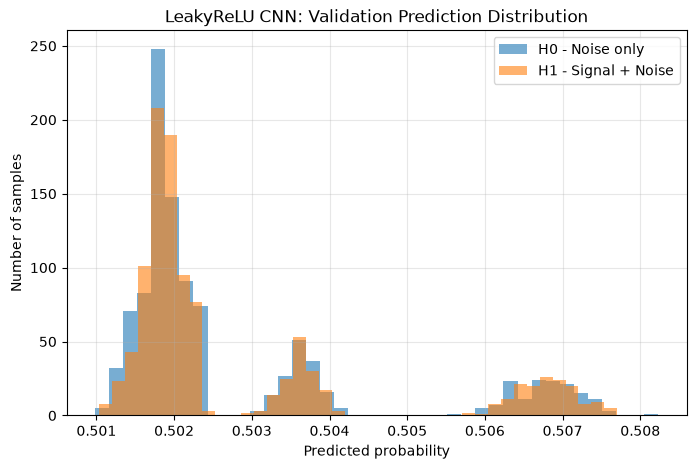

In [25]:
# Compare probability distributions for H0 and H1

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    val_probs[y_val == 0],
    bins=40,
    alpha=0.6,
    label="H0 - Noise only"
)

plt.hist(
    val_probs[y_val == 1],
    bins=40,
    alpha=0.6,
    label="H1 - Signal + Noise"
)

plt.xlabel("Predicted probability")
plt.ylabel("Number of samples")
plt.title("LeakyReLU CNN: Validation Prediction Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [27]:
# Stage 21.1: Load Rayleigh fading dataset

rayleigh_data = np.load("rayleigh_fading_dataset.npz")

X_rayleigh_complex = rayleigh_data["X"]
y_rayleigh = rayleigh_data["y"]
snr_rayleigh = rayleigh_data["snr"]

print("Rayleigh Dataset Loaded Successfully")

print("X shape:", X_rayleigh_complex.shape)
print("y shape:", y_rayleigh.shape)
print("SNR shape:", snr_rayleigh.shape)

print("Unique labels:", np.unique(y_rayleigh))
print("SNR levels:", np.unique(snr_rayleigh))

print("H0 samples:", np.sum(y_rayleigh == 0))
print("H1 samples:", np.sum(y_rayleigh == 1))

Rayleigh Dataset Loaded Successfully
X shape: (14000, 256)
y shape: (14000,)
SNR shape: (14000,)
Unique labels: [0 1]
SNR levels: [-20 -15 -10  -5   0   5  10]
H0 samples: 7000
H1 samples: 7000


In [28]:
# Stage 21.2: Convert Rayleigh complex IQ data

X_rayleigh_iq = np.stack(
    [
        np.real(X_rayleigh_complex),
        np.imag(X_rayleigh_complex)
    ],
    axis=-1
).astype(np.float32)

print("Rayleigh IQ conversion completed")

print("Input shape:", X_rayleigh_iq.shape)
print("Data type:", X_rayleigh_iq.dtype)

print("I-channel mean:", np.mean(X_rayleigh_iq[:, :, 0]))
print("Q-channel mean:", np.mean(X_rayleigh_iq[:, :, 1]))

print("I-channel std:", np.std(X_rayleigh_iq[:, :, 0]))
print("Q-channel std:", np.std(X_rayleigh_iq[:, :, 1]))

Rayleigh IQ conversion completed
Input shape: (14000, 256, 2)
Data type: float32
I-channel mean: -0.0018363202
Q-channel mean: 0.000456884
I-channel std: 3.268482
Q-channel std: 3.2716944


In [30]:
# Stage 21.3: Create Rayleigh statistical validation splits

seeds = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

rayleigh_splits = {}

for seed in seeds:

    train_idx, temp_idx = train_test_split(
        np.arange(len(y_rayleigh)),
        test_size=0.30,
        random_state=seed,
        stratify=[
            f"{label}_{s}"
            for label, s in zip(y_rayleigh, snr_rayleigh)
        ]
    )

    val_idx, test_idx = train_test_split(
        temp_idx,
        test_size=0.50,
        random_state=seed,
        stratify=[
            f"{y_rayleigh[i]}_{snr_rayleigh[i]}"
            for i in temp_idx
        ]
    )

    rayleigh_splits[seed] = (
        train_idx,
        val_idx,
        test_idx
    )

print("Rayleigh splits created successfully.\n")

for seed, (train_idx, val_idx, test_idx) in rayleigh_splits.items():

    print(
        f"Seed {seed}: "
        f"Train={len(train_idx)}, "
        f"Validation={len(val_idx)}, "
        f"Test={len(test_idx)}"
    )

Rayleigh splits created successfully.

Seed 10: Train=9800, Validation=2100, Test=2100
Seed 20: Train=9800, Validation=2100, Test=2100
Seed 30: Train=9800, Validation=2100, Test=2100
Seed 40: Train=9800, Validation=2100, Test=2100
Seed 50: Train=9800, Validation=2100, Test=2100
Seed 60: Train=9800, Validation=2100, Test=2100
Seed 70: Train=9800, Validation=2100, Test=2100
Seed 80: Train=9800, Validation=2100, Test=2100
Seed 90: Train=9800, Validation=2100, Test=2100
Seed 100: Train=9800, Validation=2100, Test=2100


In [31]:
# Stage 21.4: Rayleigh channel-wise standardization

rayleigh_scaled_data = {}

for seed in seeds:

    train_idx, val_idx, test_idx = rayleigh_splits[seed]

    X_train = X_rayleigh_iq[train_idx]
    X_val = X_rayleigh_iq[val_idx]
    X_test = X_rayleigh_iq[test_idx]

    y_train = y_rayleigh[train_idx]
    y_val = y_rayleigh[val_idx]
    y_test = y_rayleigh[test_idx]

    # Calculate statistics using training data only
    channel_mean = np.mean(
        X_train,
        axis=(0, 1),
        keepdims=True
    )

    channel_std = np.std(
        X_train,
        axis=(0, 1),
        keepdims=True
    )

    channel_std = np.maximum(channel_std, 1e-8)

    # Apply training statistics to all splits
    X_train_scaled = (X_train - channel_mean) / channel_std
    X_val_scaled = (X_val - channel_mean) / channel_std
    X_test_scaled = (X_test - channel_mean) / channel_std

    rayleigh_scaled_data[seed] = {
        "X_train": X_train_scaled,
        "X_val": X_val_scaled,
        "X_test": X_test_scaled,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test,
        "channel_mean": channel_mean,
        "channel_std": channel_std
    }

print("Rayleigh standardization completed.\n")

for seed in seeds:
    data = rayleigh_scaled_data[seed]

    print(
        f"Seed {seed}: "
        f"Train mean={np.mean(data['X_train']):.6f}, "
        f"Train std={np.std(data['X_train']):.6f}"
    )

Rayleigh standardization completed.

Seed 10: Train mean=-0.000000, Train std=1.002143
Seed 20: Train mean=-0.000000, Train std=1.002141
Seed 30: Train mean=0.000000, Train std=1.002184
Seed 40: Train mean=-0.000000, Train std=1.002064
Seed 50: Train mean=0.000000, Train std=1.002107
Seed 60: Train mean=0.000000, Train std=1.002123
Seed 70: Train mean=-0.000000, Train std=1.002086
Seed 80: Train mean=-0.000000, Train std=1.002203
Seed 90: Train mean=-0.000000, Train std=1.002116
Seed 100: Train mean=-0.000000, Train std=1.002176


In [32]:
# Stage 21.5: Ten-seed Rayleigh CNN statistical validation

rayleigh_cnn_results = []

for seed in seeds:

    print(f"\nTraining Rayleigh CNN | Seed {seed}")

    tf.keras.utils.set_random_seed(seed)

    data = rayleigh_scaled_data[seed]

    cnn = build_cnn()

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    )

    history = cnn.fit(
        data["X_train"],
        data["y_train"],
        validation_data=(
            data["X_val"],
            data["y_val"]
        ),
        epochs=40,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    # Validation-based threshold calibration
    val_probs = cnn.predict(
        data["X_val"],
        verbose=0
    ).ravel()

    val_h0_probs = val_probs[data["y_val"] == 0]

    threshold = np.percentile(
        val_h0_probs,
        95,
        method="higher"
    )

    # Untouched test evaluation
    test_probs = cnn.predict(
        data["X_test"],
        verbose=0
    ).ravel()

    test_pred = (test_probs > threshold).astype(int)

    y_test = data["y_test"]

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        test_pred
    ).ravel()

    accuracy = accuracy_score(y_test, test_pred)
    pd_value = tp / (tp + fn)
    pfa = fp / (fp + tn)
    pm = fn / (fn + tp)
    auc = roc_auc_score(y_test, test_probs)

    rayleigh_cnn_results.append({
        "Seed": seed,
        "Accuracy": accuracy,
        "Pd": pd_value,
        "Pfa": pfa,
        "Pm": pm,
        "ROC_AUC": auc,
        "Threshold": threshold,
        "Epochs": len(history.history["loss"])
    })

    print(
        f"Accuracy={accuracy:.4f} | "
        f"Pd={pd_value:.4f} | "
        f"Pfa={pfa:.4f} | "
        f"Pm={pm:.4f} | "
        f"AUC={auc:.4f} | "
        f"Epochs={len(history.history['loss'])}"
    )

print("\nAll ten Rayleigh CNN runs completed.")


Training Rayleigh CNN | Seed 10
Accuracy=0.6810 | Pd=0.4086 | Pfa=0.0467 | Pm=0.5914 | AUC=0.8014 | Epochs=40

Training Rayleigh CNN | Seed 20
Accuracy=0.6695 | Pd=0.3838 | Pfa=0.0448 | Pm=0.6162 | AUC=0.7826 | Epochs=40

Training Rayleigh CNN | Seed 30
Accuracy=0.6486 | Pd=0.3448 | Pfa=0.0476 | Pm=0.6552 | AUC=0.7663 | Epochs=40

Training Rayleigh CNN | Seed 40
Accuracy=0.6395 | Pd=0.3362 | Pfa=0.0571 | Pm=0.6638 | AUC=0.7479 | Epochs=40

Training Rayleigh CNN | Seed 50
Accuracy=0.6900 | Pd=0.4286 | Pfa=0.0486 | Pm=0.5714 | AUC=0.8099 | Epochs=40

Training Rayleigh CNN | Seed 60
Accuracy=0.6543 | Pd=0.3686 | Pfa=0.0600 | Pm=0.6314 | AUC=0.7615 | Epochs=40

Training Rayleigh CNN | Seed 70
Accuracy=0.6476 | Pd=0.3486 | Pfa=0.0533 | Pm=0.6514 | AUC=0.7619 | Epochs=40

Training Rayleigh CNN | Seed 80
Accuracy=0.6414 | Pd=0.3581 | Pfa=0.0752 | Pm=0.6419 | AUC=0.7545 | Epochs=40

Training Rayleigh CNN | Seed 90
Accuracy=0.6824 | Pd=0.4067 | Pfa=0.0419 | Pm=0.5933 | AUC=0.8035 | Epochs=40



In [33]:
# Stage 21.7: Save Rayleigh CNN statistical validation results

rayleigh_cnn_df = pd.DataFrame(rayleigh_cnn_results)

metrics = [
    "Accuracy",
    "Pd",
    "Pfa",
    "Pm",
    "ROC_AUC"
]

rayleigh_cnn_summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [
        rayleigh_cnn_df[m].mean() for m in metrics
    ],
    "Std": [
        rayleigh_cnn_df[m].std() for m in metrics
    ]
})

# Save detailed and summary results
rayleigh_cnn_df.to_csv(
    "cnn_statistical_validation_rayleigh_all_runs.csv",
    index=False
)

rayleigh_cnn_summary.to_csv(
    "cnn_statistical_validation_rayleigh_summary.csv",
    index=False
)

print("Detailed results:")
display(rayleigh_cnn_df.round(4))

print("\nSummary (Mean ± Std):")
display(rayleigh_cnn_summary.round(4))

print("\nBoth CSV files saved successfully.")

Detailed results:


,Seed,Accuracy,Pd,Pfa,Pm,ROC_AUC,Threshold,Epochs
0,10,0.6810,0.4086,0.0467,0.5914,0.8014,0.5297,40
1,20,0.6695,0.3838,0.0448,0.6162,0.7826,0.5495,40
2,30,0.6486,0.3448,0.0476,0.6552,0.7663,0.5761,40
3,40,0.6395,0.3362,0.0571,0.6638,0.7479,0.6236,40
4,50,0.6900,0.4286,0.0486,0.5714,0.8099,0.5770,40
5,60,0.6543,0.3686,0.0600,0.6314,0.7615,0.5498,40
6,70,0.6476,0.3486,0.0533,0.6514,0.7619,0.5837,40
7,80,0.6414,0.3581,0.0752,0.6419,0.7545,0.6066,40
8,90,0.6824,0.4067,0.0419,0.5933,0.8035,0.5256,40
9,100,0.6686,0.3762,0.0390,0.6238,0.7798,0.5062,40



Summary (Mean ± Std):


,Metric,Mean,Std
0,Accuracy,0.6623,0.0184
1,Pd,0.3760,0.0308
2,Pfa,0.0514,0.0106
3,Pm,0.6240,0.0308
4,ROC_AUC,0.7769,0.0220



Both CSV files saved successfully.


In [34]:
# Stage 22.1: Load AWGN and Rayleigh statistical summaries

awgn_cnn_summary = pd.read_csv(
    "cnn_statistical_validation_awgn_summary.csv"
)

rayleigh_cnn_summary = pd.read_csv(
    "cnn_statistical_validation_rayleigh_summary.csv"
)

awgn_ml_summary = pd.read_csv(
    "statistical_validation_awgn_summary.csv"
)

rayleigh_ml_summary = pd.read_csv(
    "statistical_validation_summary.csv"
)

print("All statistical summary files loaded successfully.")

print("\nAWGN CNN Summary:")
display(awgn_cnn_summary.round(4))

print("\nRayleigh CNN Summary:")
display(rayleigh_cnn_summary.round(4))

print("\nAWGN ML Summary:")
display(awgn_ml_summary.round(4))

print("\nRayleigh ML Summary:")
display(rayleigh_ml_summary.round(4))

All statistical summary files loaded successfully.

AWGN CNN Summary:


,Metric,Mean,Std
0,Accuracy,0.7648,0.0279
1,Pd,0.5419,0.0597
2,Pfa,0.0123,0.0172
3,Pm,0.4581,0.0597
4,ROC_AUC,0.8979,0.0132



Rayleigh CNN Summary:


,Metric,Mean,Std
0,Accuracy,0.6623,0.0184
1,Pd,0.3760,0.0308
2,Pfa,0.0514,0.0106
3,Pm,0.6240,0.0308
4,ROC_AUC,0.7769,0.0220



AWGN ML Summary:


,Channel,Model,Accuracy_mean,Accuracy_std,Pd_mean,Pd_std,Pfa_mean,Pfa_std,Pm_mean,Pm_std,ROC_AUC_mean,ROC_AUC_std
0,AWGN,Logistic Regression,0.6721,0.0077,0.3932,0.0159,0.0490,0.0042,0.6068,0.0159,0.833,0.0058
1,AWGN,Random Forest,0.8240,0.0040,0.6934,0.0102,0.0453,0.0073,0.3066,0.0102,0.940,0.0027



Rayleigh ML Summary:


,Channel,Model,Accuracy_mean,Accuracy_std,Pd_mean,Pd_std,Pfa_mean,Pfa_std,Pm_mean,Pm_std,ROC_AUC_mean,ROC_AUC_std
0,AWGN,Logistic Regression,0.6721,0.0077,0.3932,0.0159,0.0490,0.0042,0.6068,0.0159,0.8330,0.0058
1,AWGN,Random Forest,0.8240,0.0040,0.6934,0.0102,0.0453,0.0073,0.3066,0.0102,0.9400,0.0027
2,Rayleigh,Logistic Regression,0.6418,0.0075,0.3339,0.0143,0.0504,0.0082,0.6661,0.0143,0.7550,0.0060
3,Rayleigh,Random Forest,0.7723,0.0034,0.5945,0.0110,0.0499,0.0076,0.4055,0.0110,0.8819,0.0031


In [35]:
# Stage 22.2: Consolidated statistical comparison

consolidated_results = []

# Extract LR and RF results
for _, row in awgn_ml_summary.iterrows():

    consolidated_results.append({
        "Channel": "AWGN",
        "Model": row["Model"],
        "Accuracy_mean": row["Accuracy_mean"],
        "Accuracy_std": row["Accuracy_std"],
        "Pd_mean": row["Pd_mean"],
        "Pd_std": row["Pd_std"],
        "Pfa_mean": row["Pfa_mean"],
        "Pfa_std": row["Pfa_std"],
        "Pm_mean": row["Pm_mean"],
        "Pm_std": row["Pm_std"],
        "ROC_AUC_mean": row["ROC_AUC_mean"],
        "ROC_AUC_std": row["ROC_AUC_std"]
    })

for _, row in rayleigh_ml_summary.iterrows():

    if row["Channel"] != "Rayleigh":
        continue

    consolidated_results.append({
        "Channel": "Rayleigh",
        "Model": row["Model"],
        "Accuracy_mean": row["Accuracy_mean"],
        "Accuracy_std": row["Accuracy_std"],
        "Pd_mean": row["Pd_mean"],
        "Pd_std": row["Pd_std"],
        "Pfa_mean": row["Pfa_mean"],
        "Pfa_std": row["Pfa_std"],
        "Pm_mean": row["Pm_mean"],
        "Pm_std": row["Pm_std"],
        "ROC_AUC_mean": row["ROC_AUC_mean"],
        "ROC_AUC_std": row["ROC_AUC_std"]
    })

# Add CNN summaries
for channel, summary in [
    ("AWGN", awgn_cnn_summary),
    ("Rayleigh", rayleigh_cnn_summary)
]:

    values = {
        row["Metric"]: (row["Mean"], row["Std"])
        for _, row in summary.iterrows()
    }

    consolidated_results.append({
        "Channel": channel,
        "Model": "1D-CNN",
        "Accuracy_mean": values["Accuracy"][0],
        "Accuracy_std": values["Accuracy"][1],
        "Pd_mean": values["Pd"][0],
        "Pd_std": values["Pd"][1],
        "Pfa_mean": values["Pfa"][0],
        "Pfa_std": values["Pfa"][1],
        "Pm_mean": values["Pm"][0],
        "Pm_std": values["Pm"][1],
        "ROC_AUC_mean": values["ROC_AUC"][0],
        "ROC_AUC_std": values["ROC_AUC"][1]
    })

consolidated_df = pd.DataFrame(consolidated_results)

consolidated_df = consolidated_df.sort_values(
    ["Channel", "Model"]
).reset_index(drop=True)

print("Consolidated statistical comparison:")
display(consolidated_df.round(4))

consolidated_df.to_csv(
    "consolidated_statistical_comparison.csv",
    index=False
)

print("\nSaved: consolidated_statistical_comparison.csv")

Consolidated statistical comparison:


,Channel,Model,Accuracy_mean,Accuracy_std,Pd_mean,Pd_std,Pfa_mean,Pfa_std,Pm_mean,Pm_std,ROC_AUC_mean,ROC_AUC_std
0,AWGN,1D-CNN,0.7648,0.0279,0.5419,0.0597,0.0123,0.0172,0.4581,0.0597,0.8979,0.0132
1,AWGN,Logistic Regression,0.6721,0.0077,0.3932,0.0159,0.0490,0.0042,0.6068,0.0159,0.8330,0.0058
2,AWGN,Random Forest,0.8240,0.0040,0.6934,0.0102,0.0453,0.0073,0.3066,0.0102,0.9400,0.0027
3,Rayleigh,1D-CNN,0.6623,0.0184,0.3760,0.0308,0.0514,0.0106,0.6240,0.0308,0.7769,0.0220
4,Rayleigh,Logistic Regression,0.6418,0.0075,0.3339,0.0143,0.0504,0.0082,0.6661,0.0143,0.7550,0.0060
5,Rayleigh,Random Forest,0.7723,0.0034,0.5945,0.0110,0.0499,0.0076,0.4055,0.0110,0.8819,0.0031



Saved: consolidated_statistical_comparison.csv


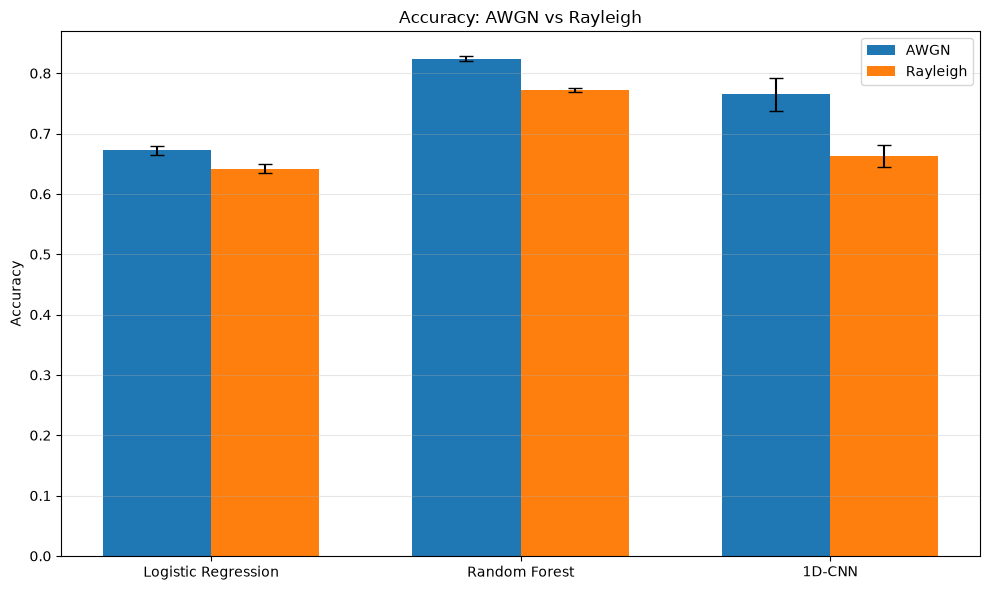

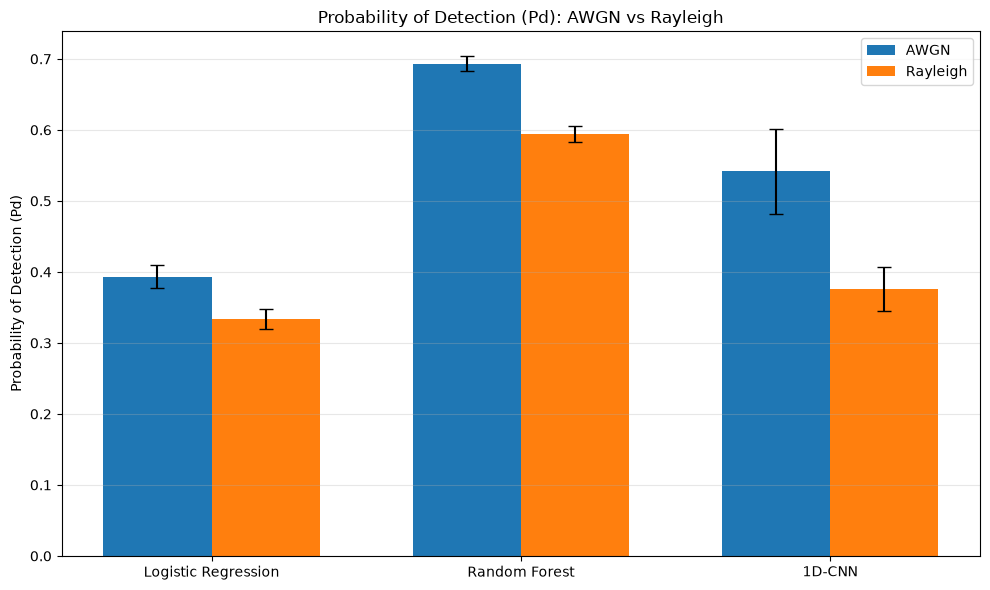

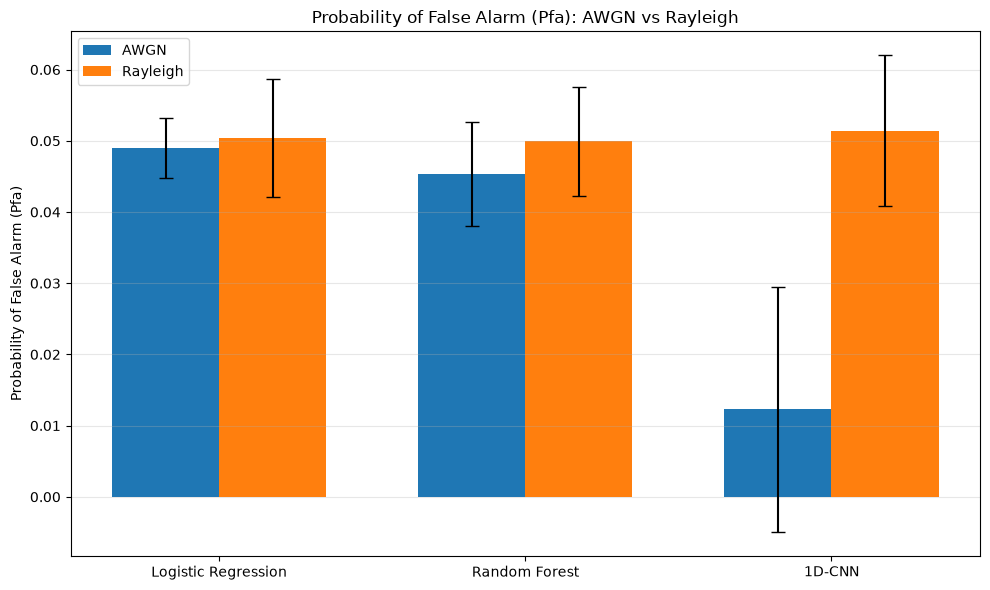

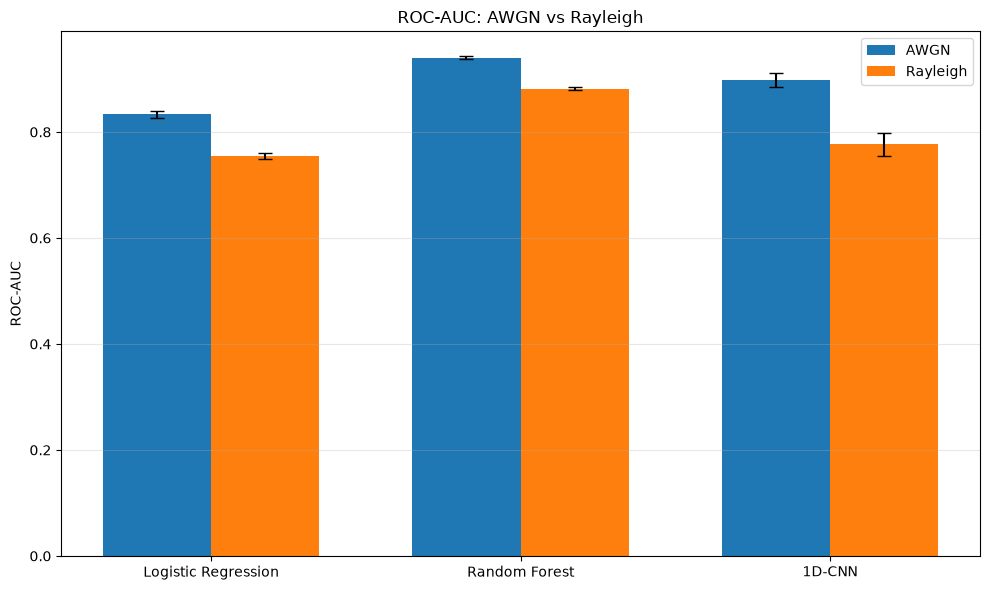

All four comparison plots saved successfully.


In [36]:
# Stage 22.3: Comparative performance plots

import matplotlib.pyplot as plt
import numpy as np

metrics_to_plot = [
    ("Accuracy", "Accuracy_mean", "Accuracy_std"),
    ("Probability of Detection (Pd)", "Pd_mean", "Pd_std"),
    ("Probability of False Alarm (Pfa)", "Pfa_mean", "Pfa_std"),
    ("ROC-AUC", "ROC_AUC_mean", "ROC_AUC_std")
]

models = ["Logistic Regression", "Random Forest", "1D-CNN"]
channels = ["AWGN", "Rayleigh"]

for title, mean_col, std_col in metrics_to_plot:

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.arange(len(models))
    width = 0.35

    for i, channel in enumerate(channels):

        subset = consolidated_df[
            consolidated_df["Channel"] == channel
        ].set_index("Model").reindex(models)

        ax.bar(
            x + (i - 0.5) * width,
            subset[mean_col],
            width,
            yerr=subset[std_col],
            capsize=5,
            label=channel
        )

    ax.set_title(f"{title}: AWGN vs Rayleigh")
    ax.set_ylabel(title)
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    filename = (
        title.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("-", "_")
    )

    plt.savefig(
        f"comparison_{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("All four comparison plots saved successfully.")

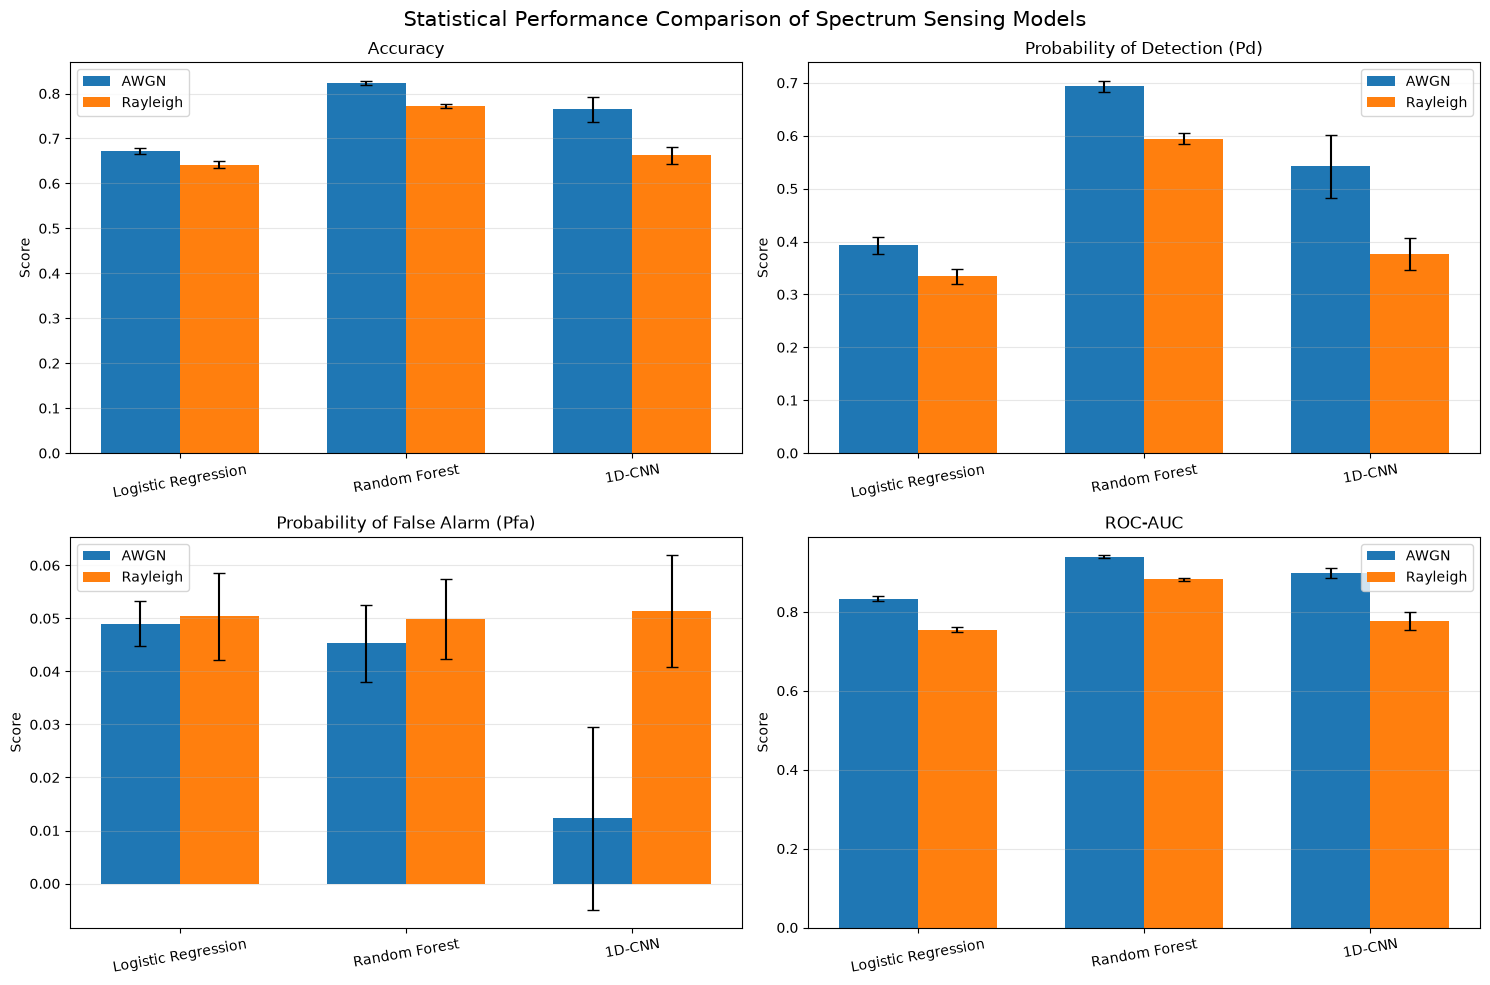

Combined comparison figure saved successfully.


In [37]:
# Stage 22.4: Combined four-panel performance figure

import matplotlib.pyplot as plt
import numpy as np

metrics = [
    ("Accuracy", "Accuracy_mean", "Accuracy_std"),
    ("Probability of Detection (Pd)", "Pd_mean", "Pd_std"),
    ("Probability of False Alarm (Pfa)", "Pfa_mean", "Pfa_std"),
    ("ROC-AUC", "ROC_AUC_mean", "ROC_AUC_std")
]

models = ["Logistic Regression", "Random Forest", "1D-CNN"]
channels = ["AWGN", "Rayleigh"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (title, mean_col, std_col) in zip(
    axes.flatten(), metrics
):

    x = np.arange(len(models))
    width = 0.35

    for i, channel in enumerate(channels):

        subset = (
            consolidated_df[
                consolidated_df["Channel"] == channel
            ]
            .set_index("Model")
            .reindex(models)
        )

        ax.bar(
            x + (i - 0.5) * width,
            subset[mean_col],
            width,
            yerr=subset[std_col],
            capsize=4,
            label=channel
        )

    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=10)
    ax.set_ylabel("Score")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

fig.suptitle(
    "Statistical Performance Comparison of Spectrum Sensing Models",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "final_consolidated_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Combined comparison figure saved successfully.")